In [3]:
import os
import numpy as np
import librosa
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten
from sklearn.metrics import accuracy_score, classification_report
import matplotlib.pyplot as plt

In [4]:
non_music_path = "dataset1/non_music"
music_path = "dataset1/music"
test_music_path ="dataset2/test/music"
test_non_music_path ="dataset2/test/non_music"

In [5]:
non_music_files = [os.path.join(non_music_path, f) for f in os.listdir(non_music_path)]
music_files = [os.path.join(music_path, f) for f in os.listdir(music_path)]
test_music_files=[os.path.join(test_music_path,f)for f in os.listdir(test_music_path)]
test_non_music_files=[os.path.join(test_non_music_path,f)for f in os.listdir(test_non_music_path)]

In [6]:
def extract_features(file_path):
    audio, sr = librosa.load(file_path)
    mfccs = librosa.feature.mfcc(y=audio, sr=sr, n_mfcc=20)
    return mfccs.flatten()

In [7]:
non_music_features = np.array([extract_features(f) for f in non_music_files])

In [8]:

music_features = np.array([extract_features(f) for f in music_files])

In [11]:
test_music_features= np.array([extract_features(f) for f in test_music_files])
test_non_music_features= np.array([extract_features(f) for f in test_non_music_files])

'\nvalidation_music_features= np.array([extract_features(f) for f in validation_music_files])\nvalidation_non_music_features= np.array([extract_features(f) for f in validation_non_music_files])'

In [12]:
non_music_labels = np.zeros(len(non_music_files))
music_labels = np.ones(len(music_files))
test_non_music_labels = np.zeros(len(test_non_music_files))
test_music_labels = np.ones(len(test_music_files))

In [14]:
X_train = np.concatenate((non_music_features, music_features))
y_train = np.concatenate((non_music_labels, music_labels))

In [ ]:
X_test= np.concatenate((test_non_music_features, test_music_features))
y_test =np.concatenate((test_non_music_labels, test_music_labels))

'\nX_val=np.concatenate((validation_non_music_features, validation_music_features))\ny_val=np.concatenate((validation_non_music_labels, validation_music_labels))'

In [16]:
model = Sequential([
    Flatten(input_shape=(X_train.shape[1],)),
    Dense(2048,activation='relu'),
    Dense(1024,activation='relu'),
    Dense(512,activation='relu'),
    Dense(256,activation='relu'),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(1, activation='sigmoid')
])

c:\Users\Amine\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [17]:
model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])

In [18]:
tf.keras.backend.clear_session()

In [19]:
model.fit(X_train, y_train, epochs=10, batch_size=64, validation_split=0.2)

Epoch 1/10
2118/2118 ━━━━━━━━━━━━━━━━━━━━ 309s 131ms/step - accuracy: 0.9240 - loss: 2.1200 - val_accuracy: 0.9368 - val_loss: 0.1736
Epoch 2/10
2118/2118 ━━━━━━━━━━━━━━━━━━━━ 268s 127ms/step - accuracy: 0.9778 - loss: 0.0663 - val_accuracy: 0.9449 - val_loss: 0.1644
Epoch 3/10
2118/2118 ━━━━━━━━━━━━━━━━━━━━ 277s 131ms/step - accuracy: 0.9809 - loss: 0.0596 - val_accuracy: 0.9573 - val_loss: 0.1569
Epoch 4/10
2118/2118 ━━━━━━━━━━━━━━━━━━━━ 278s 131ms/step - accuracy: 0.9852 - loss: 0.0452 - val_accuracy: 0.9647 - val_loss: 0.1245
Epoch 5/10
2118/2118 ━━━━━━━━━━━━━━━━━━━━ 278s 131ms/step - accuracy: 0.9884 - loss: 0.0361 - val_accuracy: 0.9555 - val_loss: 0.1579
Epoch 6/10
2118/2118 ━━━━━━━━━━━━━━━━━━━━ 278s 131ms/step - accuracy: 0.9877 - loss: 0.0383 - val_accuracy: 0.9462 - val_loss: 0.1722
Epoch 7/10
2118/2118 ━━━━━━━━━━━━━━━━━━━━ 277s 131ms/step - accuracy: 0.9905 - loss: 0.0297 - val_accuracy: 0.9819 - val_loss: 0.0613
Epoch 8/10
2118/2118 ━━━━━━━━━━━━━━━━━━━━ 278s 131ms/step - ac

In [20]:
y_pred = (model.predict(X_test) > 0.9).astype("int32")
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step
Accuracy: 0.9564


In [21]:
print("Classification Report:")
print(classification_report(y_test, y_pred))

Classification Report:
              precision    recall  f1-score   support

         0.0       0.94      0.98      0.96      5000
         1.0       0.98      0.94      0.96      5000

    accuracy                           0.96     10000
   macro avg       0.96      0.96      0.96     10000
weighted avg       0.96      0.96      0.96     10000



In [23]:
from sklearn.metrics import confusion_matrix

In [24]:
conf_matrix = confusion_matrix(y_test, y_pred)
conf_matrix_percent = conf_matrix.astype('float') / conf_matrix.sum(axis=1)[:, np.newaxis] * 100

print("Confusion Matrix:")
print(conf_matrix)

Confusion Matrix:
[[4883  117]
 [ 319 4681]]


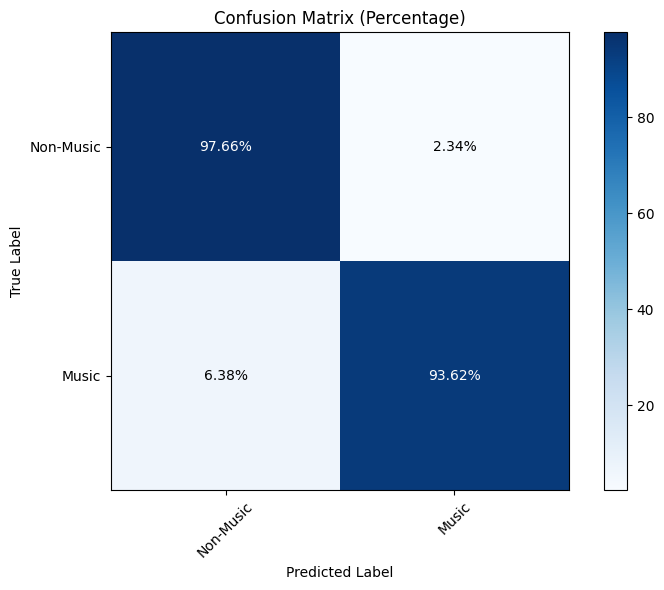

In [25]:
plt.figure(figsize=(8, 6))
plt.imshow(conf_matrix_percent, cmap=plt.cm.Blues)
plt.title('Confusion Matrix (Percentage)')
plt.colorbar()

classes = ['Non-Music', 'Music']
tick_marks = np.arange(len(classes))
plt.xticks(tick_marks, classes, rotation=45)
plt.yticks(tick_marks, classes)

thresh = conf_matrix_percent.max() / 2.
for i, j in np.ndindex(conf_matrix_percent.shape):
    plt.text(j, i, format(conf_matrix_percent[i, j], '.2f') + '%',
             ha="center", va="center",
             color="white" if conf_matrix_percent[i, j] > thresh else "black")

plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.tight_layout()
plt.savefig('ConfusionMatrixCNN2')
plt.show()

In [32]:
%pip install pydot

In [35]:
from tensorflow.keras.utils import plot_model

In [37]:
output_model_path = "CNN_model_architecture_2.png"
plot_model(model, to_file=output_model_path, show_shapes=True, show_layer_names=True)


You must install pydot (`pip install pydot`) for `plot_model` to work.


In [26]:
#model.save("CNNmodelForMp3_97%.h5")